# Milestone 2: Data Understanding & Cleaning
**Project:** Energy Efficient AI  |  **Dataset:** `energy_efficient_dataset.csv`  |  **Target:** `efficiency_class` (3 classes)

**What this notebook does**
1. Loads the raw data and takes a **before** snapshot.
2. Runs data quality checks: missing values, duplicates, data types, value ranges, outliers.
3. Applies cleaning decisions, each one with a clear reason.
4. Takes an **after** snapshot and compares before vs after.
5. Saves the clean dataset to `../data/clean_data.csv` and the charts to `figures/`.

## Step 0: Setup

In [1]:
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Folder for saved charts
os.makedirs("figures", exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

## Step 1: Load the raw data

In [2]:
# Load the raw dataset from the shared data folder. We never edit this file, we only work on copies.
df_raw = pd.read_csv("../data/energy_efficient_dataset.csv")
print(f"Raw dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Raw dataset: 7167 rows, 12 columns


,ID,System_Load_Level,Power_Draw_Watts,Memory_Usage_MB,CPU_Utilization_Percent,GPU_Utilization_Percent,Execution_Time_ms,Throughput_ops_per_sec,Energy_Consumption_kWh,Thermal_Output_C,Resource_Utilization_Index,Efficiency_Class
0,1,0.822379,172.758993,8484.416855,63.501764,7.461321,351.589068,1368.291944,2.572335,43.106626,0.438742,Moderate_Efficiency
1,2,0.816021,285.086823,4149.960984,22.421314,68.842454,431.508959,1356.261452,9.753689,74.457810,0.419990,Low_Efficiency
2,3,0.448547,107.840571,695.421292,84.388839,43.996473,428.200098,212.917860,5.877830,64.245964,0.814711,Moderate_Efficiency
3,4,0.859491,151.089436,13895.010522,68.329937,84.417851,154.048529,391.544439,6.560060,86.402010,0.987481,Low_Efficiency
4,5,0.540144,128.592669,10915.551614,64.706458,80.707858,189.069332,268.652949,8.338474,53.439116,0.751681,Low_Efficiency


In [3]:
# Decision: make all column names lowercase
# Reason: one consistent style avoids typing mistakes (Efficiency_Class vs efficiency_class)
df = df_raw.copy()
df.columns = df.columns.str.lower()

target = "efficiency_class"
num_cols = [c for c in df.select_dtypes("number").columns if c != "id"]  # numeric features (no id)
print("Target column:", target)
print("Numeric feature columns:", len(num_cols))

Target column: efficiency_class
Numeric feature columns: 10


## Step 2: Before-cleaning snapshot

In [4]:
# Helper functions used for the before/after comparison
def iqr_bounds(s):
    # IQR rule: a value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Valid ranges, based on what each column means
valid_ranges = {
    "system_load_level": (0, 1),
    "cpu_utilization_percent": (0, 100),
    "gpu_utilization_percent": (0, 100),
    "resource_utilization_index": (0, 1),
}

def snapshot(frame):
    cols = [c for c in frame.select_dtypes("number").columns if c != "id"]
    outliers = 0
    for c in cols:
        lo, hi = iqr_bounds(frame[c])
        outliers += int(((frame[c] < lo) | (frame[c] > hi)).sum())
    out_of_range = 0
    for c, (lo, hi) in valid_ranges.items():
        out_of_range += int(((frame[c] < lo) | (frame[c] > hi)).sum())
    return {
        "Rows": len(frame),
        "Columns": frame.shape[1],
        "Missing values": int(frame.isnull().sum().sum()),
        "Duplicate rows": int(frame.drop(columns="id", errors="ignore").duplicated().sum()),
        "Outliers (IQR rule)": outliers,
        "Out-of-range values": out_of_range,
    }

before = snapshot(df)
stats_before = df.describe().T.round(3)
print("BEFORE cleaning:", before)
stats_before

BEFORE cleaning: {'Rows': 7167, 'Columns': 12, 'Missing values': 0, 'Duplicate rows': 0, 'Outliers (IQR rule)': 0, 'Out-of-range values': 0}


,count,mean,std,min,25%,50%,75%,max
id,7167.0,3584.000,2069.079,1.000,1792.500,3584.000,5375.500,7167.000
system_load_level,7167.0,0.547,0.260,0.100,0.320,0.547,0.773,1.000
power_draw_watts,7167.0,198.442,86.472,50.016,123.590,196.759,273.738,349.902
memory_usage_mb,7167.0,8578.782,4569.666,516.007,4700.689,8639.709,12491.778,16382.807
cpu_utilization_percent,7167.0,55.037,25.821,10.004,32.709,55.170,77.043,99.973
gpu_utilization_percent,7167.0,49.705,28.736,0.001,24.671,49.853,74.254,99.979
execution_time_ms,7167.0,255.078,141.948,10.008,132.780,254.402,378.853,499.946
throughput_ops_per_sec,7167.0,1014.943,563.977,50.183,521.126,1009.696,1508.884,1999.946
energy_consumption_kwh,7167.0,5.092,2.857,0.100,2.638,5.129,7.575,9.998
thermal_output_c,7167.0,59.963,17.282,30.003,45.286,59.782,74.973,89.996


## Step 3: Data quality checks

### 3.1 Missing values

In [5]:
# Count missing values in every column (not only the total)
missing = df.isnull().sum()
missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2),
})
print("Total missing values:", int(missing.sum()))
missing_report

Total missing values: 0


,missing_count,missing_percent
id,0,0.0
system_load_level,0,0.0
power_draw_watts,0,0.0
memory_usage_mb,0,0.0
cpu_utilization_percent,0,0.0
gpu_utilization_percent,0,0.0
execution_time_ms,0,0.0
throughput_ops_per_sec,0,0.0
energy_consumption_kwh,0,0.0
thermal_output_c,0,0.0


In [6]:
# Decision: no action for missing values
# Reason: the check found 0 missing values in all 12 columns, so there is nothing to fill or drop.
# Filling or dropping would only change real data without a reason.

### 3.2 Duplicate rows

In [7]:
# Check 1: duplicates across ALL columns (including id)
dup_all = int(df.duplicated().sum())

# Check 2: duplicates when we ignore id
# Reason: id is different for every row, so check 1 can never find a duplicate.
# Ignoring id shows if two rows have the same measurements.
dup_no_id = int(df.drop(columns="id").duplicated().sum())

print("Duplicates (all columns):        ", dup_all)
print("Duplicates (ignoring id column): ", dup_no_id)
print("Is id unique for every row?      ", df["id"].is_unique)

Duplicates (all columns):         0
Duplicates (ignoring id column):  0
Is id unique for every row?       True


In [8]:
# Decision: no action for duplicates
# Reason: 0 duplicates were found, even after ignoring id, so there is nothing to remove.

### 3.3 Data types

In [9]:
# Check that every column has the type we expect
types = pd.DataFrame({"dtype": df.dtypes.astype(str)})
print(types.to_string())

# Check the target column: which values does it have, and is there extra whitespace?
print("\nTarget values:", sorted(df[target].unique()))
print("Values with extra spaces:", int((df[target] != df[target].str.strip()).sum()))

                              dtype
id                            int64
system_load_level           float64
power_draw_watts            float64
memory_usage_mb             float64
cpu_utilization_percent     float64
gpu_utilization_percent     float64
execution_time_ms           float64
throughput_ops_per_sec      float64
energy_consumption_kwh      float64
thermal_output_c            float64
resource_utilization_index  float64
efficiency_class                str

Target values: ['High_Efficiency', 'Low_Efficiency', 'Moderate_Efficiency']
Values with extra spaces: 0


In [10]:
# Decision: no change to data types
# Reason: all 10 measurement columns (and id) are already numeric, and the target is text
# with 3 clean labels (no typos, no extra spaces). The target is encoded to numbers later,
# when we build the model, not during cleaning.

### 3.4 Value ranges (impossible values)

In [11]:
# Check that values are inside the range that makes sense for each column
rows = []
for c, (lo, hi) in valid_ranges.items():
    rows.append({
        "column": c,
        "expected_range": f"{lo} to {hi}",
        "min_found": round(df[c].min(), 3),
        "max_found": round(df[c].max(), 3),
        "out_of_range": int(((df[c] < lo) | (df[c] > hi)).sum()),
    })
range_report = pd.DataFrame(rows)

# Other measurements (watts, MB, ms, kWh, ...) can never be negative
other_cols = [c for c in num_cols if c not in valid_ranges]
negatives = int((df[other_cols] < 0).sum().sum())

print("Negative values in the other numeric columns:", negatives)
range_report

Negative values in the other numeric columns: 0


,column,expected_range,min_found,max_found,out_of_range
0,system_load_level,0 to 1,0.100,1.000,0
1,cpu_utilization_percent,0 to 100,10.004,99.973,0
2,gpu_utilization_percent,0 to 100,0.001,99.979,0
3,resource_utilization_index,0 to 1,0.201,1.000,0


In [12]:
# Decision: no action for value ranges
# Reason: every value is inside its valid range and there are no negative values.

### 3.5 Outliers

In [13]:
# Count outliers in each numeric column with the IQR rule
rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({
        "column": c,
        "lower_limit": round(lo, 3),
        "upper_limit": round(hi, 3),
        "min": round(df[c].min(), 3),
        "max": round(df[c].max(), 3),
        "outliers": n,
    })
outlier_report = pd.DataFrame(rows)
print("Total outliers:", int(outlier_report["outliers"].sum()))
outlier_report

Total outliers: 0


,column,lower_limit,upper_limit,min,max,outliers
0,system_load_level,-0.360,1.453,0.100,1.000,0
1,power_draw_watts,-101.631,498.959,50.016,349.902,0
2,memory_usage_mb,-6985.943,24178.410,516.007,16382.807,0
3,cpu_utilization_percent,-33.792,143.544,10.004,99.973,0
4,gpu_utilization_percent,-49.705,148.630,0.001,99.979,0
5,execution_time_ms,-236.329,747.961,10.008,499.946,0
6,throughput_ops_per_sec,-960.509,2990.519,50.183,1999.946,0
7,energy_consumption_kwh,-4.768,14.981,0.100,9.998,0
8,thermal_output_c,0.757,119.502,30.003,89.996,0
9,resource_utilization_index,-0.197,1.401,0.201,1.000,0


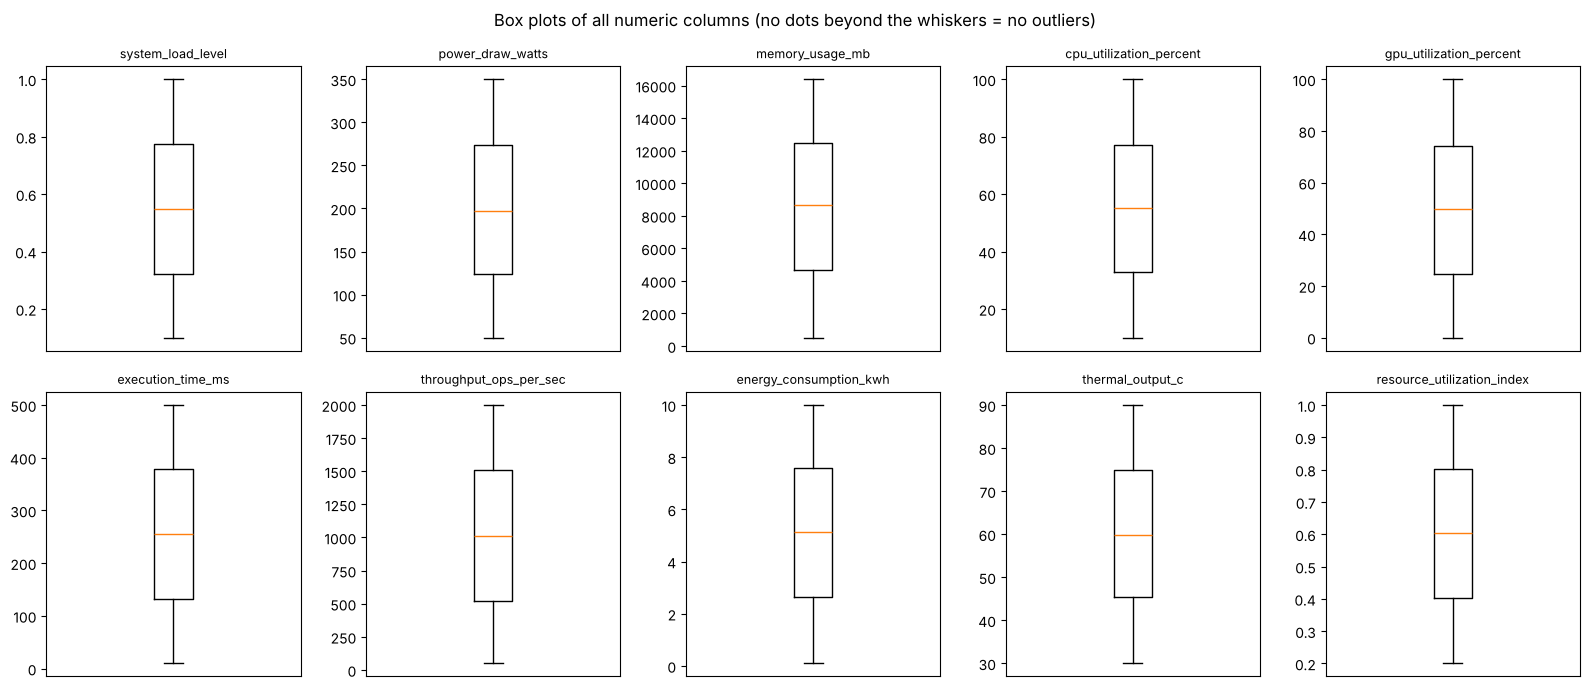

In [14]:
# Box plots: a visual check for outliers (dots beyond the whiskers would be outliers)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, c in zip(axes.flat, num_cols):
    ax.boxplot(df[c])
    ax.set_title(c, fontsize=9)
    ax.set_xticks([])
fig.suptitle("Box plots of all numeric columns (no dots beyond the whiskers = no outliers)", fontsize=12)
plt.tight_layout()
plt.savefig("figures/boxplots.png", dpi=120)
plt.show()

In [15]:
# Decision: no outliers are capped or removed
# Reason: the IQR rule found 0 outliers in all 10 columns and the box plots confirm it.
# We do not change real data when there is no problem to fix.

### 3.6 Target variable distribution (class balance)

In [16]:
# How many rows belong to each efficiency class?
counts = df[target].value_counts()
percent = (df[target].value_counts(normalize=True) * 100).round(2)
target_summary = pd.DataFrame({"Count": counts, "Percentage (%)": percent})
print("Largest class / smallest class ratio:", round(counts.max() / counts.min(), 1))
target_summary

Largest class / smallest class ratio: 6.3


,Count,Percentage (%)
efficiency_class,,
Moderate_Efficiency,3619,50.50
Low_Efficiency,2972,41.47
High_Efficiency,576,8.04


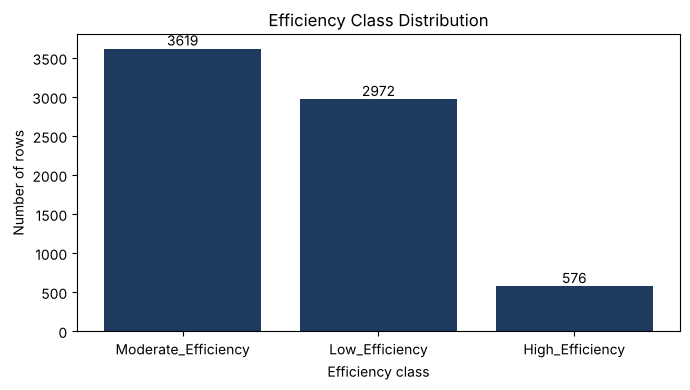

In [17]:
# Bar chart of the target classes
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index, counts.values, color="#1E3A5F")
ax.set_title("Efficiency Class Distribution")
ax.set_xlabel("Efficiency class")
ax.set_ylabel("Number of rows")
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, str(v), ha="center")
plt.tight_layout()
plt.savefig("figures/target_distribution.png", dpi=120)
plt.show()

## Step 4: Cleaning decisions

In [18]:
# Decision: drop the id column
# Reason: id is only a row number (unique for every row). It carries no information about
# efficiency, and a model could wrongly learn from it.
df_clean = df.drop(columns="id")
print("Columns before:", df.shape[1], "| Columns after:", df_clean.shape[1])

Columns before: 12 | Columns after: 11


In [19]:
# Decision log: every finding and what we decided, in one table
decision_log = pd.DataFrame([
    ["Column names",        "Mixed capital letters",        "Converted to lowercase",       "Consistent names, fewer typing mistakes"],
    ["Missing values",      "0 in all columns",             "No action",                    "Nothing to fix"],
    ["Duplicate rows",      "0 (also 0 ignoring id)",       "No action",                    "Nothing to remove"],
    ["Data types",          "All numeric, target is text",  "No action",                    "Types already match the data"],
    ["Value ranges",        "All values valid, no negatives","No action",                   "Nothing impossible found"],
    ["Outliers",            "0 by IQR rule and box plots",  "No capping or removal",        "No outliers, real values kept"],
    ["id column",           "Unique number for every row",  "Dropped",                      "No predictive information"],
    ["Class imbalance",     "High_Efficiency is only 8%",   "Not changed (left for modeling)", "It is a real feature of the data, not an error"],
], columns=["Area", "What we found", "Decision", "Reason"])
decision_log

,Area,What we found,Decision,Reason
0,Column names,Mixed capital letters,Converted to lowercase,"Consistent names, fewer typing mistakes"
1,Missing values,0 in all columns,No action,Nothing to fix
2,Duplicate rows,0 (also 0 ignoring id),No action,Nothing to remove
3,Data types,"All numeric, target is text",No action,Types already match the data
4,Value ranges,"All values valid, no negatives",No action,Nothing impossible found
5,Outliers,0 by IQR rule and box plots,No capping or removal,"No outliers, real values kept"
6,id column,Unique number for every row,Dropped,No predictive information
7,Class imbalance,High_Efficiency is only 8%,Not changed (left for modeling),"It is a real feature of the data, not an error"


## Step 5: After-cleaning snapshot and comparison

In [20]:
# Take the same snapshot again on the cleaned data and compare
after = snapshot(df_clean)
comparison = pd.DataFrame({"Before": before, "After": after})
comparison

,Before,After
Rows,7167,7167
Columns,12,11
Missing values,0,0
Duplicate rows,0,0
Outliers (IQR rule),0,0
Out-of-range values,0,0


In [21]:
# Summary statistics AFTER cleaning
stats_after = df_clean.describe().T.round(3)
stats_after

,count,mean,std,min,25%,50%,75%,max
system_load_level,7167.0,0.547,0.260,0.100,0.320,0.547,0.773,1.000
power_draw_watts,7167.0,198.442,86.472,50.016,123.590,196.759,273.738,349.902
memory_usage_mb,7167.0,8578.782,4569.666,516.007,4700.689,8639.709,12491.778,16382.807
cpu_utilization_percent,7167.0,55.037,25.821,10.004,32.709,55.170,77.043,99.973
gpu_utilization_percent,7167.0,49.705,28.736,0.001,24.671,49.853,74.254,99.979
execution_time_ms,7167.0,255.078,141.948,10.008,132.780,254.402,378.853,499.946
throughput_ops_per_sec,7167.0,1014.943,563.977,50.183,521.126,1009.696,1508.884,1999.946
energy_consumption_kwh,7167.0,5.092,2.857,0.100,2.638,5.129,7.575,9.998
thermal_output_c,7167.0,59.963,17.282,30.003,45.286,59.782,74.973,89.996
resource_utilization_index,7167.0,0.601,0.229,0.201,0.402,0.605,0.802,1.000


In [22]:
# Compare statistics before and after for the columns that still exist
same = stats_before.drop(index="id").equals(stats_after)
print("Statistics of all remaining columns are identical before and after:", same)
print("Only difference: the 'id' column was removed (12 columns -> 11 columns).")

Statistics of all remaining columns are identical before and after: True
Only difference: the 'id' column was removed (12 columns -> 11 columns).


## Step 6: Save the clean dataset

In [23]:
# Save the clean dataset to a NEW file (the raw file stays untouched)
df_clean.to_csv("../data/clean_data.csv", index=False)

# Reload it to confirm it was saved correctly
check = pd.read_csv("../data/clean_data.csv")
print("data/clean_data.csv saved:", check.shape[0], "rows,", check.shape[1], "columns")
print("Missing values in saved file:", int(check.isnull().sum().sum()))

data/clean_data.csv saved: 7167 rows, 11 columns
Missing values in saved file: 0


## Remaining data quality issues (not fixed) and why

1. **Class imbalance.** `High_Efficiency` has only 576 rows (about 8%) while `Moderate_Efficiency` has 3,619 (about 50%).
   We did **not** fix it now. It is real information about the data, not a mistake. Changing it (for example with oversampling) belongs to the
   modeling step, and it must be done only on the training data. Planned handling: stratified train/test split, class weights, and
   evaluation with F1-score (not accuracy alone).
2. **No outliers and no missing values.** The dataset is already clean, so no values were changed. All numeric columns are spread evenly
   between round minimum and maximum values (for example thermal output 30 to 90, execution time 10 to 500), which suggests the data may be
   synthetic or pre-cleaned. We confirmed it by checking, not by assuming.
3. **Weak signal in most features.** The average of most features is almost the same in all three classes. Only `execution_time_ms` and
   `energy_consumption_kwh` differ clearly between classes. This is not a cleaning issue. It is a question for the next step (Exploratory Data
   Analysis), where we will check feature relationships and whether these two columns define the class too directly.